# Harmonic and Morse oscillators

**Judy Wu · Experiment C3 — IB Chem A**

A computational chemistry coursework project exploring vibrational wave functions, probability densities, expectation values and vibration–rotation coupling.

**Run:** Upload this notebook to Colab and run all cells. No GPU or external data files are required. If imports are missing, use `%pip install numpy scipy matplotlib` in a separate cell. Locally, install `requirements.txt` and select that environment as the kernel.

**Preparation:** The original file is unchanged. This copy removes the university login identifier, fixes numerical/units issues and clarifies interpretation. Historical output is retained separately in `results/`; the displayed outputs and exported figures are from the prepared notebook. See `PREPARATION_NOTES.md` for changes.

In [1]:
from pathlib import Path
from functools import lru_cache
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants, integrate, special, stats

FIGURES = Path("figures")
RESULTS = Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 120})

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=150)
    plt.show()
    plt.close()

# # 3.1 The harmonic oscillator

In [2]:
# Harmonic section uses dimensionless coordinate x and hbar = mu = omega = 1.
# No physical SI displacement is implied by x in this section.
ho_states = np.arange(6)

### Defining unnormalised wavefunctions $\psi_v(x)$ for $n = 0,1,2,3,4,5$

In [3]:
def psi_v(v, x):
    return special.eval_hermite(v, x) * np.exp(-0.5 * np.asarray(x)**2)

### Defining normalised wavefunctions $\phi_v(x)$ for $n = 0,1,2,3,4,5$

In [4]:
# Cache each normalisation integral instead of repeating it inside every evaluation.
@lru_cache(maxsize=None)
def ho_normalisation(v):
    norm, _ = integrate.quad(lambda x: psi_v(v, x)**2, -np.inf, np.inf)
    return 1 / np.sqrt(norm)

def phi_v(v, x):
    return ho_normalisation(v) * psi_v(v, x)

ho_norms = np.array([integrate.quad(lambda x: phi_v(int(v), x)**2, -np.inf, np.inf)[0]
                     for v in ho_states])
np.testing.assert_allclose(ho_norms, 1, atol=1e-10, rtol=0)
print("Normalisation integrals for v=0,...,5:", ho_norms)

Normalisation integrals for v=0,...,5: [1. 1. 1. 1. 1. 1.]


### Plot of each wavefunction $\phi_v(x)$ and its square

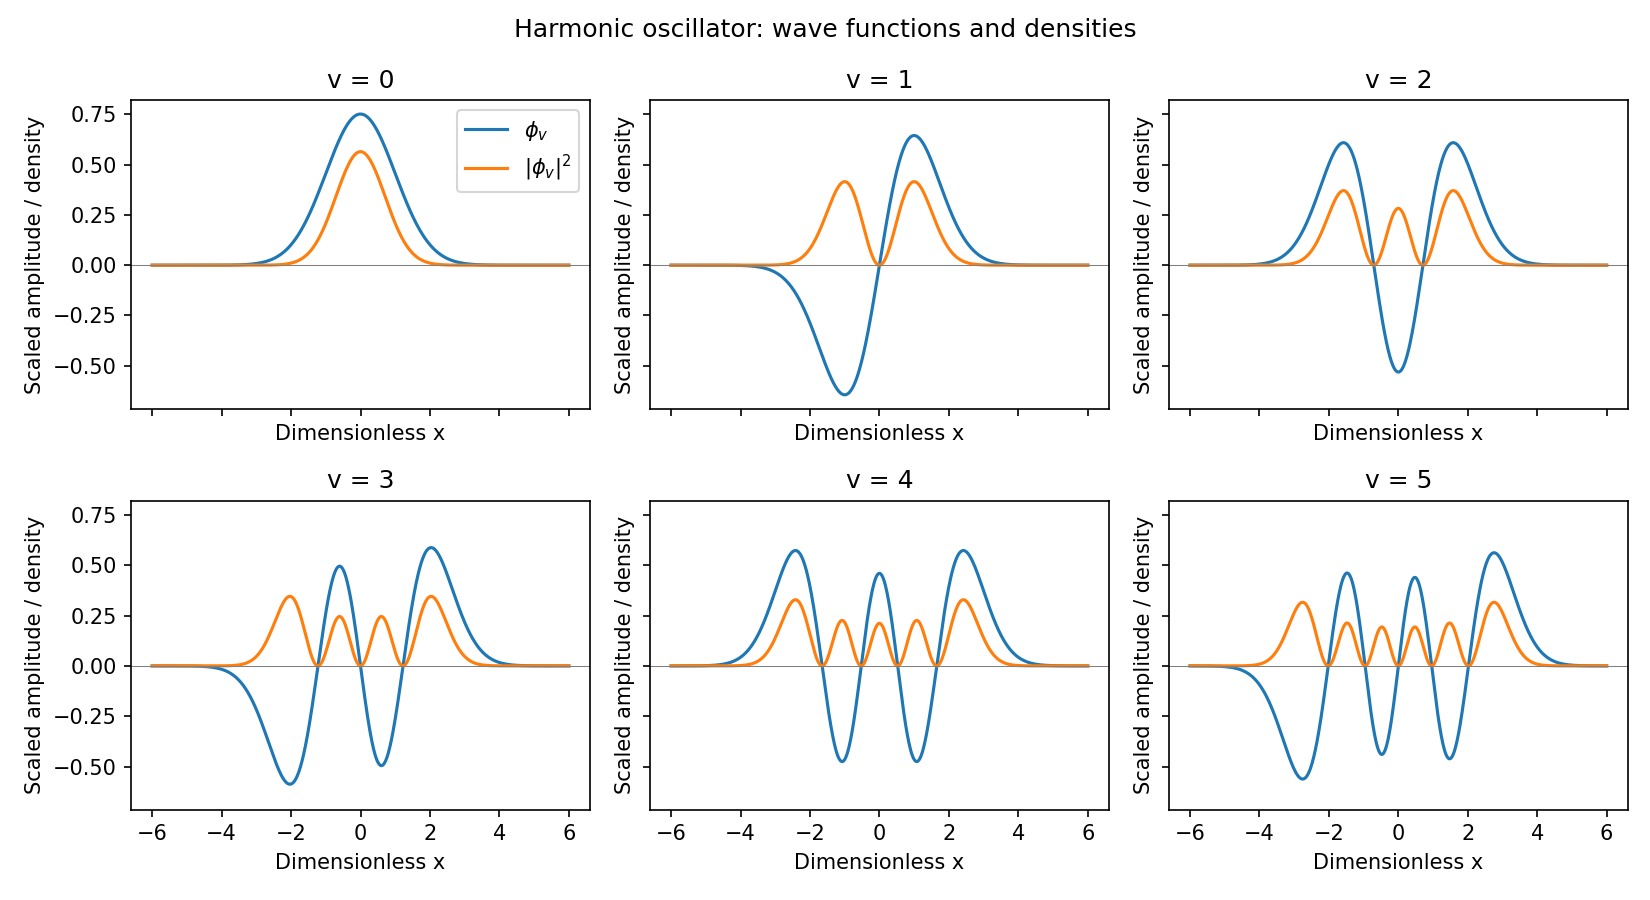

In [5]:
x = np.linspace(-6, 6, 800)
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for v, ax in zip(ho_states, axes.flat):
    wave = phi_v(int(v), x)
    ax.plot(x, wave, label=r'$\phi_v$')
    ax.plot(x, wave**2, label=r'$|\phi_v|^2$')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_title(f'v = {v}')
    ax.set_xlabel('Dimensionless x')
    ax.set_ylabel('Scaled amplitude / density')
axes[0, 0].legend()
fig.suptitle('Harmonic oscillator: wave functions and densities')
save_figure('harmonic_states')

### # Nodes and probability density

The physicists' Hermite polynomial of degree v has v distinct real zeros, giving v wave-function nodes. The probability density is even about x=0 for every state.

The spatial spread increases with v. Individual stationary-state densities remain oscillatory; a classical-like distribution emerges after suitable averaging at high quantum number, not because the oscillations literally disappear. The six plotted states alone do not establish a high-energy limit.

### Calculating $<x^2>$ of $\phi_v(x)$ and plotting it against $v$

In [6]:
x2_values = np.array([integrate.quad(lambda x: x*x*phi_v(int(v), x)**2,
                                    -np.inf, np.inf)[0] for v in ho_states])
x_values = np.array([integrate.quad(lambda x: x*phi_v(int(v), x)**2,
                                   -np.inf, np.inf)[0] for v in ho_states])
np.testing.assert_allclose(x2_values, ho_states + 0.5, atol=1e-9, rtol=0)
np.testing.assert_allclose(x_values, 0, atol=1e-10, rtol=0)

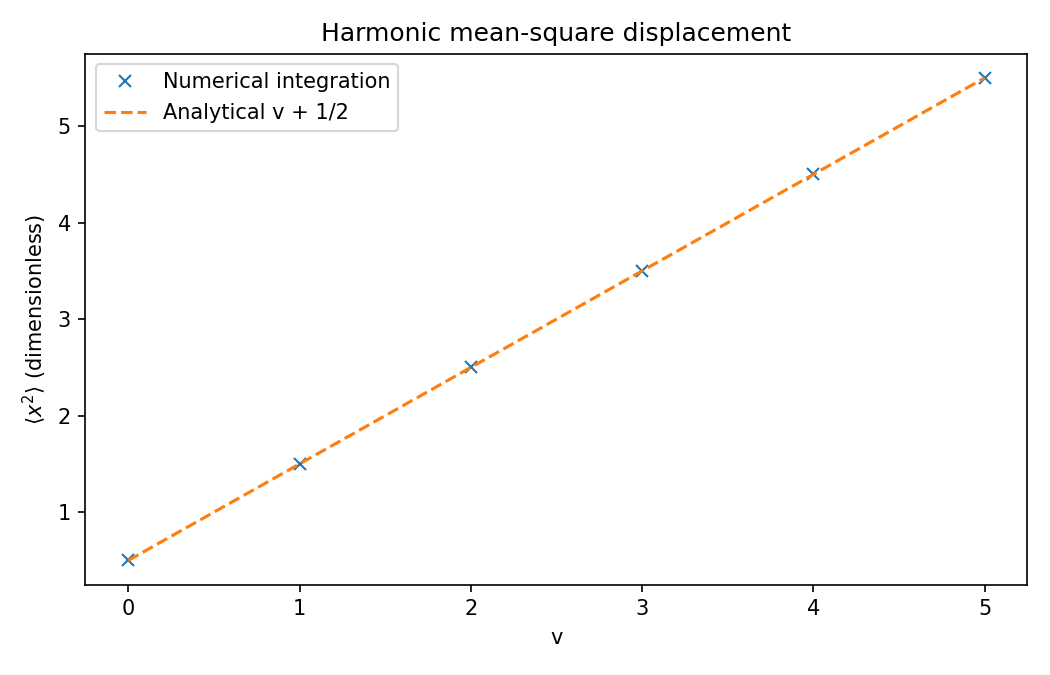

In [7]:
plt.figure()
plt.plot(ho_states, x2_values, 'x', label='Numerical integration')
plt.plot(ho_states, ho_states + 0.5, '--', label='Analytical v + 1/2')
plt.xlabel('v')
plt.ylabel(r'$\langle x^2\rangle$ (dimensionless)')
plt.title('Harmonic mean-square displacement')
plt.legend()
save_figure('harmonic_mean_square')

The numerical checks give $\langle x\rangle=0$ and $\langle x^2\rangle=v+1/2$ in the chosen dimensionless units. The first follows from the even probability density and the odd integrand $x|\phi_v(x)|^2$.

### Calculating the classical turning point $x_{class}$ of $\phi_v(x)$ and plotting the probability of penetration into the non-classical region against $v$

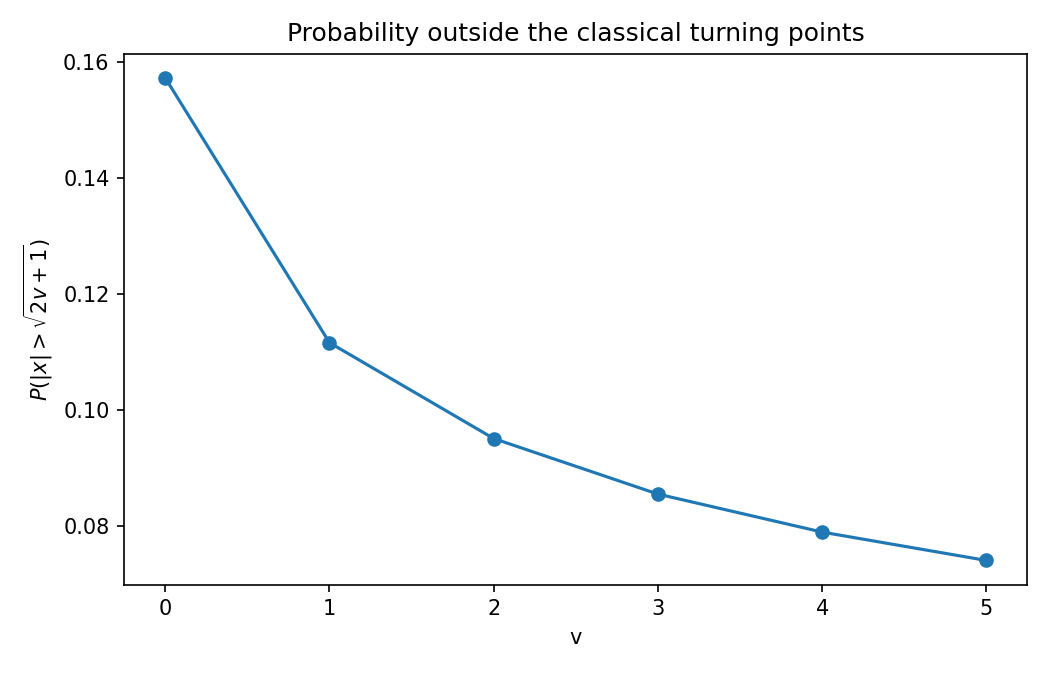

In [8]:
penetration = []
for v in ho_states:
    x_class = np.sqrt(2*v + 1)
    tail, _ = integrate.quad(lambda x: phi_v(int(v), x)**2, x_class, np.inf)
    penetration.append(2*tail)
penetration = np.array(penetration)
np.testing.assert_allclose(penetration[0], special.erfc(1), atol=1e-10, rtol=0)
assert np.all((penetration >= 0) & (penetration <= 1))
plt.figure()
plt.plot(ho_states, penetration, 'o-')
plt.xlabel('v')
plt.ylabel(r'$P(|x|>\sqrt{2v+1})$')
plt.title('Probability outside the classical turning points')
save_figure('harmonic_penetration')
np.savetxt(RESULTS / 'harmonic_summary.csv',
           np.column_stack([ho_states, ho_norms, x_values, x2_values, penetration]),
           delimiter=',', header='v,normalisation,mean_x,mean_x_squared,tail_probability', comments='')

For the states v=0,...,5 considered here, the integrated probability beyond the classical turning points decreases with v. This refers to probability in the coordinate tails, not an area outside a potential-energy parabola on the same axes.

## 3.2 The Morse oscillator


### 3.2.1 Plotting the potential energy function for Morse oscillator $V_M(x)$ and harmonic oscillator $V_H(r)$

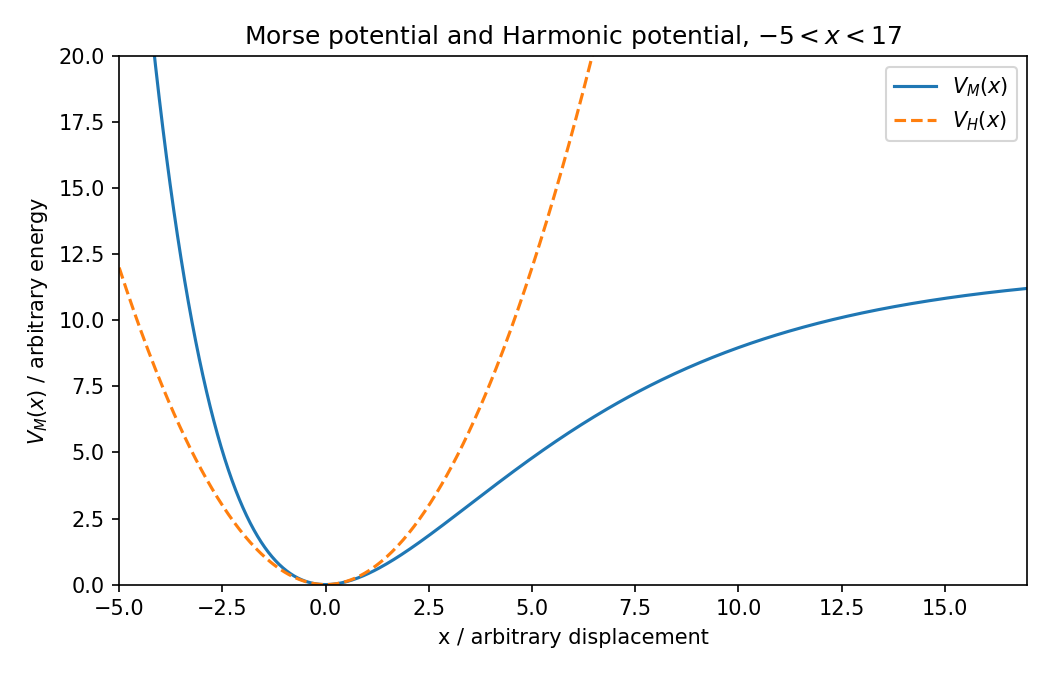

In [9]:
plt.figure()
#Defining some constants
beta_demo = 0.2
depth_demo = 12

#Plotting Morse oscillator and harmonic oscillator
x = np.linspace(-5, 17, 500)

def morse_potential(x,beta_demo,depth_demo):
  return depth_demo*(1-np.exp(-beta_demo*x))**2

def HO_potential(x):
  K_m = 2*depth_demo*beta_demo**2
  return 0.5*K_m*x**2

plt.plot(x,morse_potential(x,beta_demo,depth_demo),label= r'$V_M(x)$',)
plt.plot(x,HO_potential(x),linestyle='--',label= r'$V_H(x)$')
plt.title(r'Morse potential and Harmonic potential, $-5<x<17$')
plt.legend(loc="upper right")
plt.xlabel('x / arbitrary displacement')
plt.ylabel(r'$V_M(x)$ / arbitrary energy')
plt.xlim([-5.0, 17.0])
plt.ylim([0.0, 20.0])
save_figure("potentials_overview")

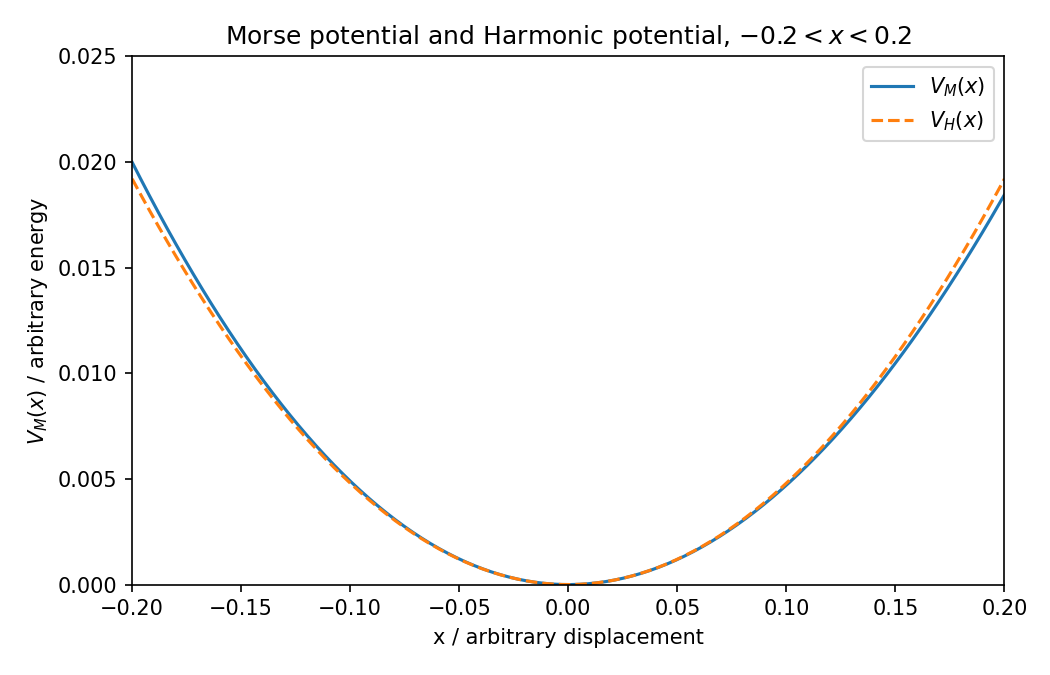

In [10]:
plt.figure()
#Plotting same graph but zoomed in
x = np.linspace(-0.2, 0.2, 200)

plt.plot(x,morse_potential(x,beta_demo,depth_demo),label= r'$V_M(x)$')
plt.plot(x,HO_potential(x),linestyle='--',label= r'$V_H(x)$')
plt.title('Morse potential and Harmonic potential, $-0.2<x<0.2$')
plt.legend(loc="upper right")
plt.xlabel('x / arbitrary displacement')
plt.ylabel(r'$V_M(x)$ / arbitrary energy')
plt.ylim([0.0, 0.025])
plt.xlim([-0.2, 0.2])
save_figure("potentials_near_equilibrium")

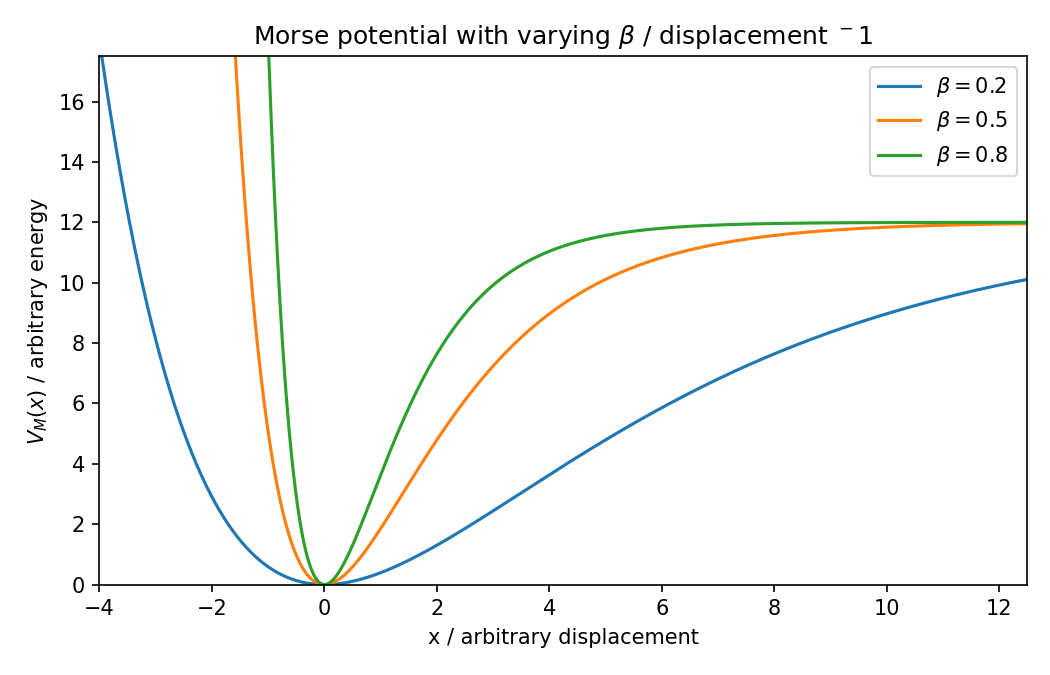

In [11]:
plt.figure()
#Plotting three Morse curves with different beta_demo values
x = np.linspace(-5, 15, 500)

plt.plot(x,morse_potential(x,0.2,depth_demo),label= r'$\beta = 0.2$')
plt.plot(x,morse_potential(x,0.5,depth_demo),label= r'$\beta = 0.5$')
plt.plot(x,morse_potential(x,0.8,depth_demo),label= r'$\beta = 0.8$')
plt.title(r'Morse potential with varying $\beta$ / displacement $^-1$')
plt.legend(loc="upper right")
plt.xlabel('x / arbitrary displacement')
plt.ylabel(r'$V_M(x)$ / arbitrary energy')
plt.xlim([-4, 12.5])
plt.ylim([0.0, 17.5])
save_figure("morse_beta_sweep")

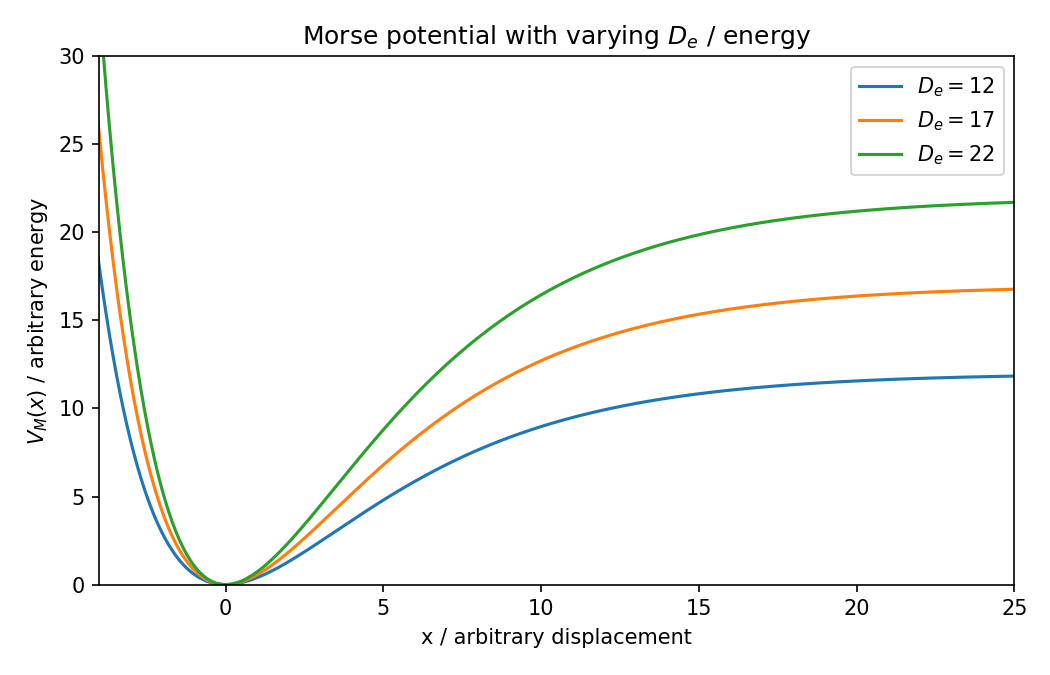

In [12]:
plt.figure()
#Plotting three Morse curves with different De values
x = np.linspace(-5, 50, 500)

plt.plot(x,morse_potential(x,beta_demo,12),label= r'$D_e = 12$',)
plt.plot(x,morse_potential(x,beta_demo,17),label= r'$D_e = 17$',)
plt.plot(x,morse_potential(x,beta_demo,22),label= r'$D_e = 22$',)
plt.title(r'Morse potential with varying $D_e$ / energy')
plt.legend(loc="upper right")
plt.xlabel('x / arbitrary displacement')
plt.ylabel(r'$V_M(x)$ / arbitrary energy')
plt.xlim([-4, 25])
plt.ylim([0.0, 30.0])
save_figure("morse_depth_sweep")

### 3.2.3 Plotting the Morse wavefunctions

### # CO parameters and a stable wave-function evaluation

Input values are retained from the supplied notebook: oxygen mass 15.995 u, carbon mass 12 u, equilibrium distance 112.8 pm, vibrational wavenumber 2170 cm⁻¹ and anharmonicity product 13.29 cm⁻¹. These are course inputs, not newly verified experimental measurements.

The amplitude uses a logarithmic normalisation and SciPy's direct Laguerre evaluation to avoid the overflow warning seen in the original polynomial construction. See [eval_genlaguerre](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.eval_genlaguerre.html) and [gammaln](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.gammaln.html).

In [13]:
c = constants.c
h = constants.h
mu = (15.995*12)/(15.995+12) * 1.66053906892e-27
re = 112.8e-12
omega_e_cm = 2170.0
omega_exe_cm = 13.29
beta = np.sqrt(8*np.pi**2*c*(omega_exe_cm*100)*mu/h)
p = omega_e_cm / omega_exe_cm

def morse_wf(v, re, p, beta, r):
    alpha = p - 2*v - 1
    if v < 0 or int(v) != v or alpha <= 0:
        raise ValueError("v must be a nonnegative integer bound state (p-2v-1 > 0)")
    z = p*np.exp(-beta*(np.asarray(r)-re))
    log_norm = 0.5*(special.gammaln(v+1) + np.log(alpha*beta)
                    - special.gammaln(p-v))
    envelope = np.exp(log_norm - z/2 + (alpha/2)*np.log(z))
    return envelope * special.eval_genlaguerre(v, alpha, z)

print(f'p = {p:.6f}')
print(f'beta = {beta:.6e} m^-1 = {beta*1e-10:.6f} angstrom^-1')

p = 163.280662
beta = 2.324913e+10 m^-1 = 2.324913 angstrom^-1


#### Plotting Morse wavefunction for $v=0,1,2,3,6,9$

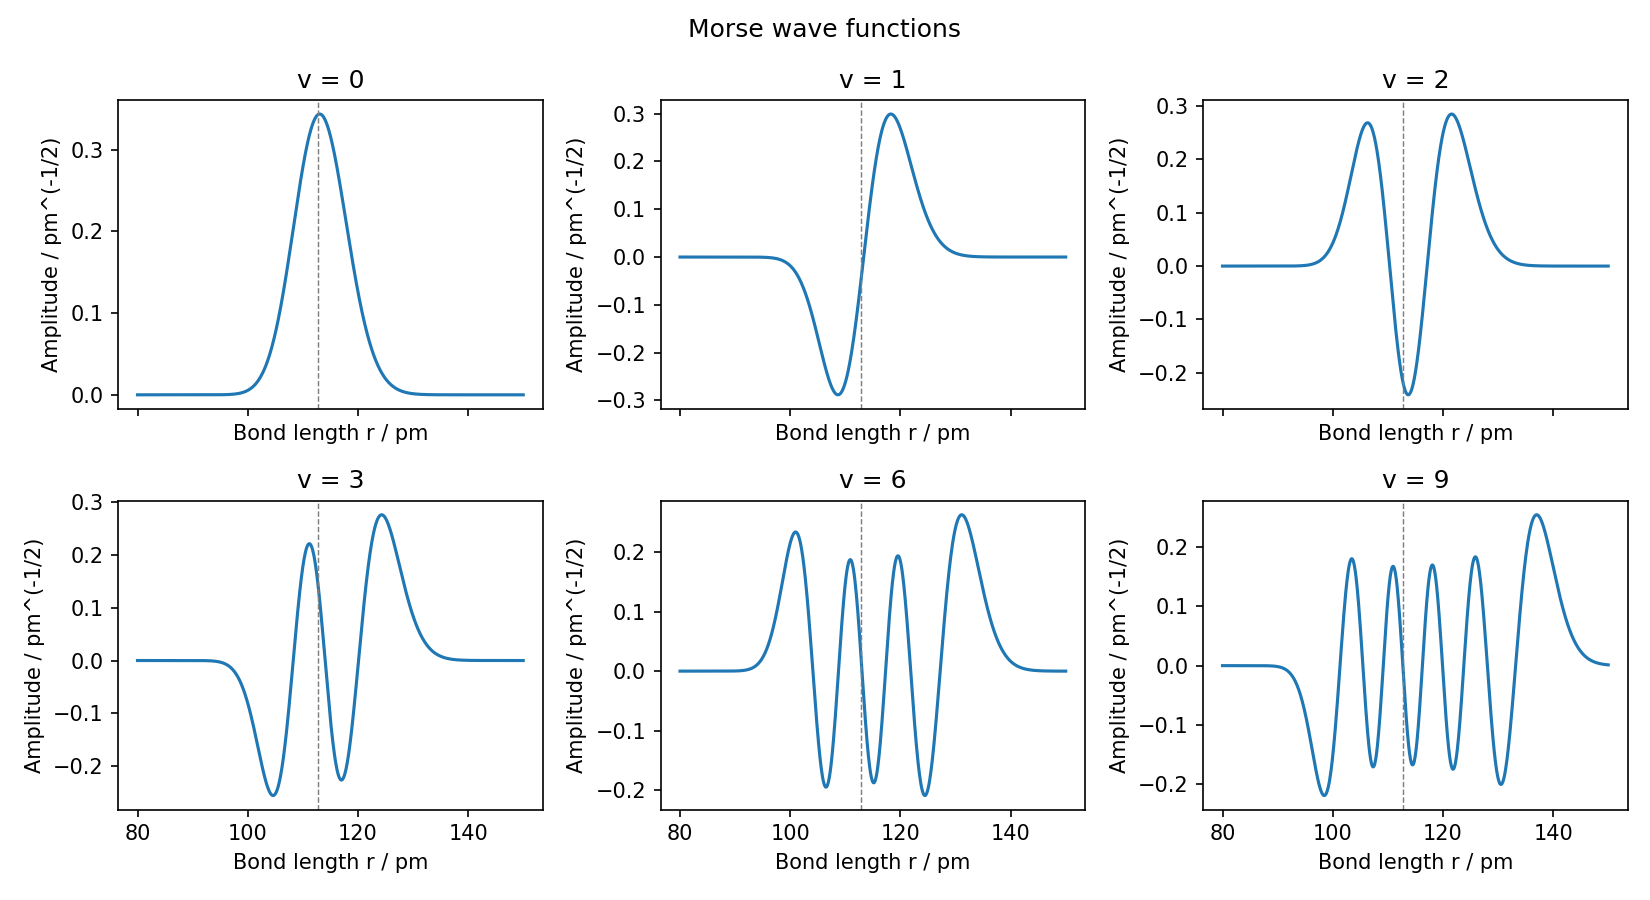

In [14]:
# Absolute bond lengths: explicitly convert picometres to metres.
r_pm = np.linspace(80, 150, 900)
r = r_pm * 1e-12
selected_states = [0, 1, 2, 3, 6, 9]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for v, ax in zip(selected_states, axes.flat):
    # Convert amplitudes to pm^(-1/2), so densities are per pm.
    wave_pm = morse_wf(v, re, p, beta, r) * 1e-6
    ax.plot(r_pm, wave_pm)
    ax.axvline(re*1e12, color='grey', ls='--', lw=0.7)
    ax.set_title(f'v = {v}')
    ax.set_xlabel('Bond length r / pm')
    ax.set_ylabel('Amplitude / pm^(-1/2)')
fig.suptitle('Morse wave functions')
save_figure('morse_states')

The plotted bound states have v nodes. The generalized Laguerre polynomial has v positive roots in its transformed coordinate z; the exponential mapping between z and r maps those roots to bond lengths. The wave function is not a polynomial of degree v in r itself.

#### Plotting squares of Morse wavefunction for $v=0,1,2,3,6,9$

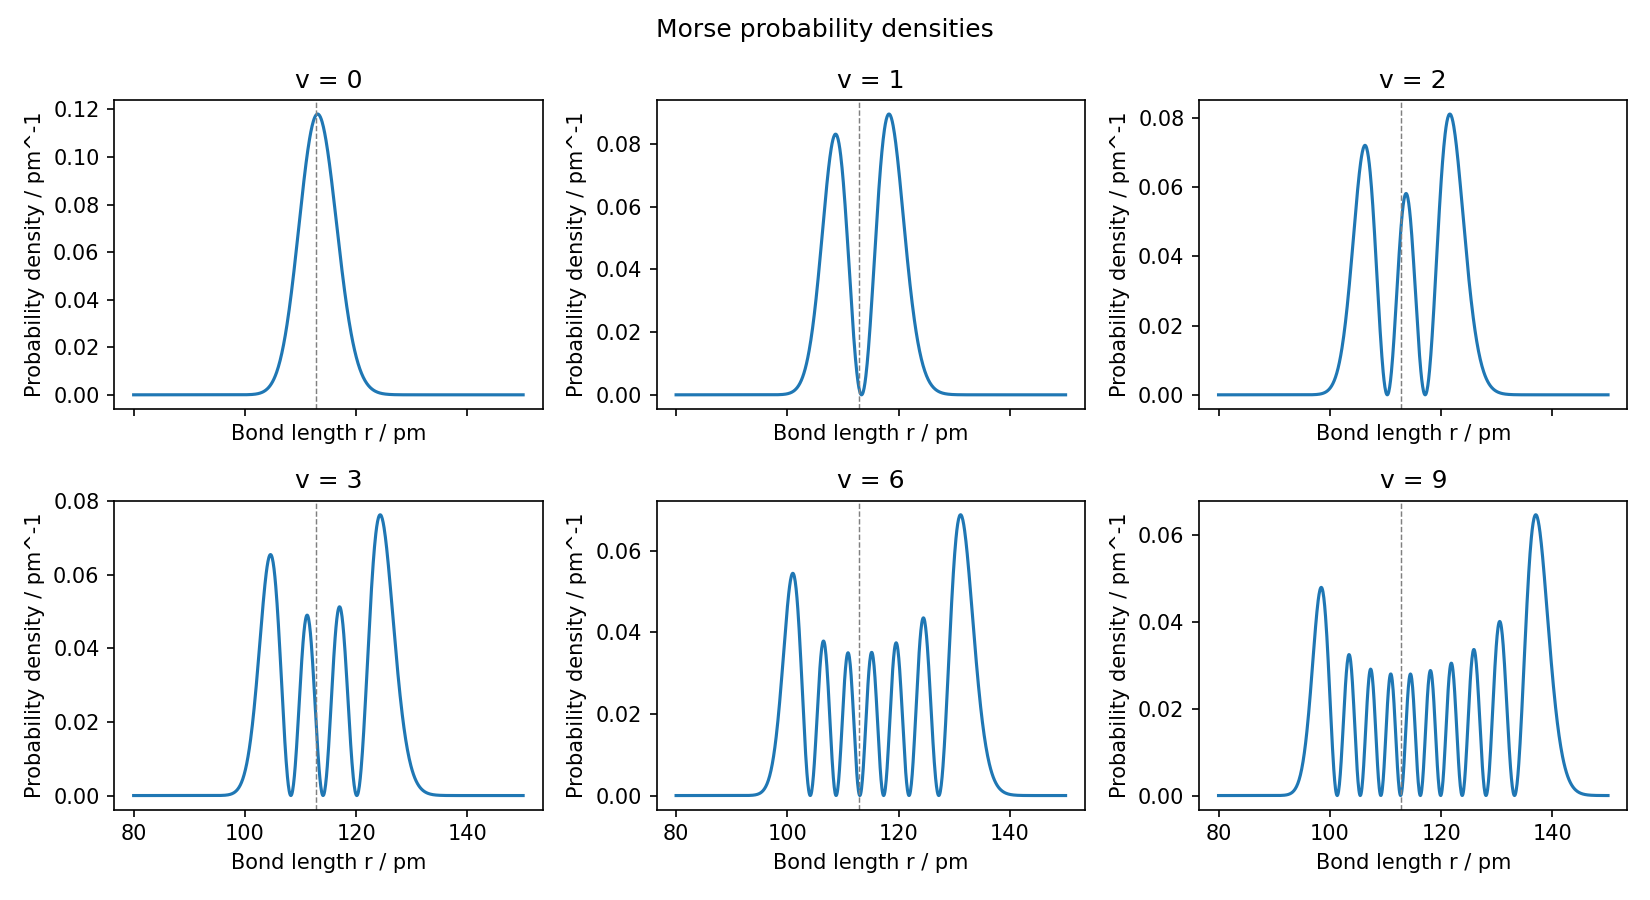

In [15]:
# Absolute bond lengths: explicitly convert picometres to metres.
r_pm = np.linspace(80, 150, 900)
r = r_pm * 1e-12
selected_states = [0, 1, 2, 3, 6, 9]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for v, ax in zip(selected_states, axes.flat):
    # Convert amplitudes to pm^(-1/2), so densities are per pm.
    wave_pm = morse_wf(v, re, p, beta, r) * 1e-6
    ax.plot(r_pm, wave_pm**2)
    ax.axvline(re*1e12, color='grey', ls='--', lw=0.7)
    ax.set_title(f'v = {v}')
    ax.set_xlabel('Bond length r / pm')
    ax.set_ylabel('Probability density / pm^-1')
fig.suptitle('Morse probability densities')
save_figure('morse_densities')

The Morse probability densities are **asymmetric** about the equilibrium bond length. Higher states spread further toward larger bond lengths, reflecting the shallower extension side of the potential. This differs from the symmetric harmonic-oscillator densities. Avoid inferring a universal monotonic change in peak height from only these selected states.

### 3.2.4 Expectation values

### # Finite-window expectation values

Integrals are evaluated in picometres to keep quantities on a sensible numerical scale. We use 60–200 pm, divide moments by the probability mass in that window, and compare against 50–220 pm. The original 80–150 pm window is also recorded for comparison.

These are finite-window Morse-model estimates. The near-equilibrium Morse model is not a radial boundary-condition model at r=0; no claim is made here about an exact inverse-square moment integrated all the way to that singular endpoint. Window stability is a numerical check for these low states, not experimental validation.

Maximum |normalisation - 1|: 1.709743457922741e-13
Maximum relative moment change for wider window: 1.5210055437364645e-14


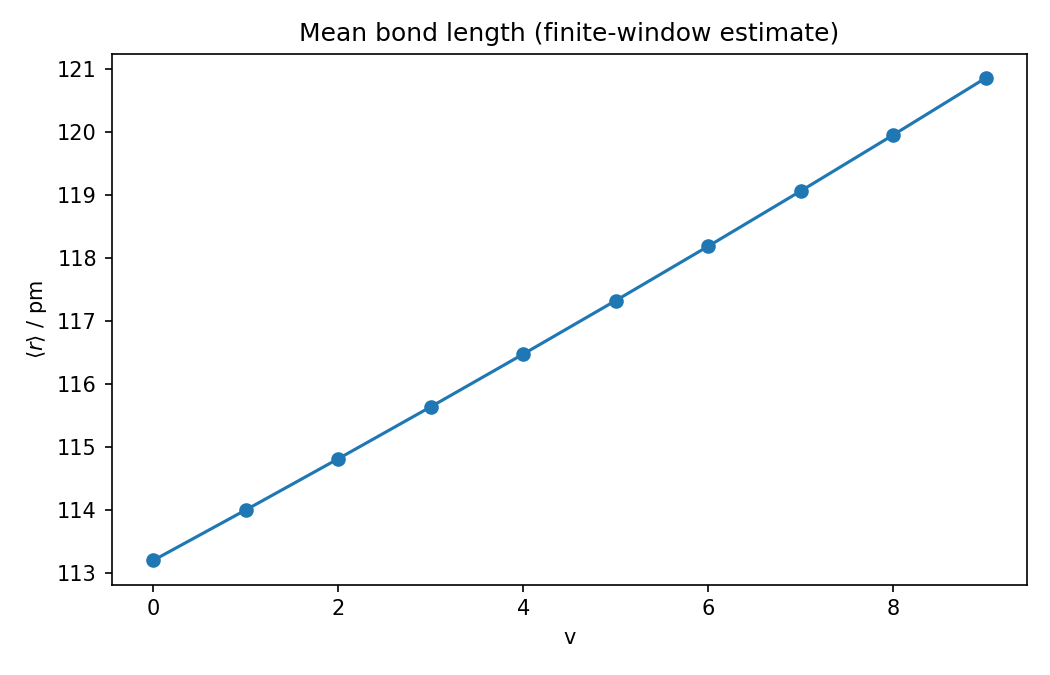

In [16]:
morse_states = np.arange(10)

def morse_moments(v, lower_pm=60, upper_pm=200):
    def density(q):
        return morse_wf(int(v), re, p, beta, q*1e-12)**2 * 1e-12
    def quad(f):
        return integrate.quad(f, lower_pm, upper_pm, epsabs=1e-11, epsrel=1e-10, limit=200)[0]
    mass = quad(density)
    mean_pm = quad(lambda q: q*density(q)) / mass
    inverse_square_pm = quad(lambda q: density(q)/(q*q)) / mass
    return mass, mean_pm, inverse_square_pm

moments = np.array([morse_moments(v) for v in morse_states])
wide_moments = np.array([morse_moments(v, 50, 220) for v in morse_states])
original_window = np.array([morse_moments(v, 80, 150) for v in morse_states])
np.testing.assert_allclose(moments[:,0], 1, atol=1e-9, rtol=0)
np.testing.assert_allclose(moments[:,1:], wide_moments[:,1:], rtol=1e-8, atol=0)
expect_r_pm = moments[:,1]
print('Maximum |normalisation - 1|:', np.max(np.abs(moments[:,0]-1)))
print('Maximum relative moment change for wider window:',
      np.max(np.abs(moments[:,1:]/wide_moments[:,1:]-1)))
plt.figure()
plt.plot(morse_states, expect_r_pm, 'o-')
plt.xlabel('v')
plt.ylabel(r'$\langle r\rangle$ / pm')
plt.title('Mean bond length (finite-window estimate)')
save_figure('morse_mean_bond_length')

The mean bond length increases across v=0,...,9 because the Morse well is asymmetric. The rotational constant used below is proportional to $\langle r^{-2}\rangle$, **not** to $1/\langle r^2\rangle$; these are different quantities.

#### Determining the value of $<\frac{1}{r^2}>_v$ for $v=0,1,2,...,9$

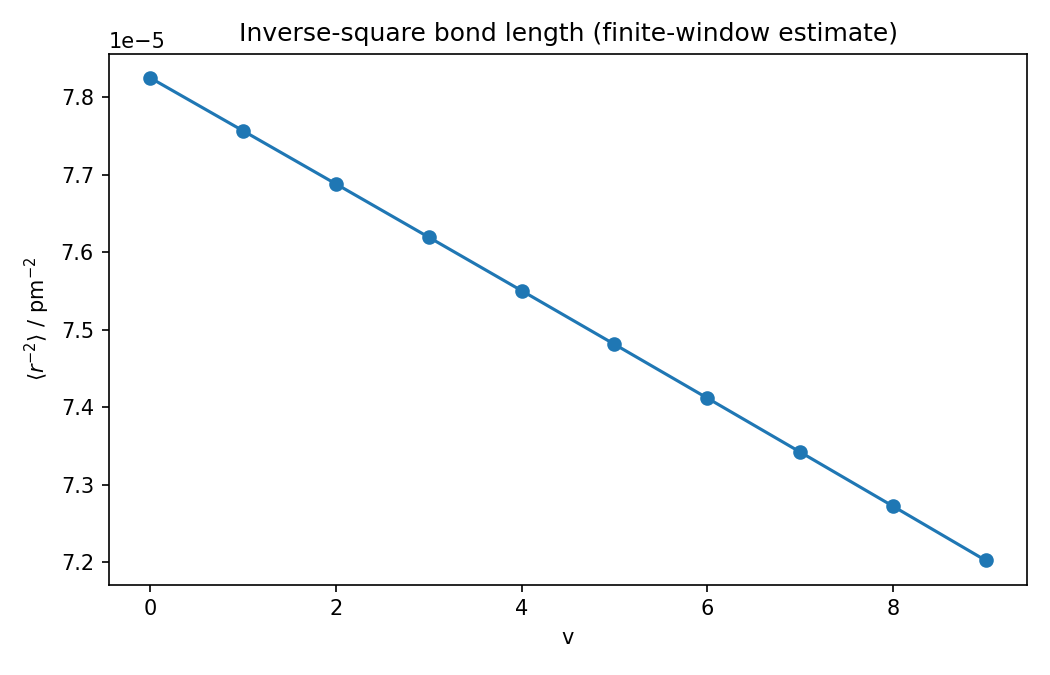

In [17]:
expect_inverse_r2 = moments[:,2] * 1e24  # pm^-2 -> m^-2
plt.figure()
plt.plot(morse_states, moments[:,2], 'o-')
plt.xlabel('v')
plt.ylabel(r'$\langle r^{-2}\rangle$ / pm$^{-2}$')
plt.title('Inverse-square bond length (finite-window estimate)')
save_figure('morse_inverse_square')

#### Determining value of $\tilde{B_v}$

In [18]:
# h/(8*pi^2*c*mu) times an SI inverse-square moment gives m^-1.
# Divide by 100 to convert m^-1 to cm^-1.
B_v = h*expect_inverse_r2 / (8*np.pi**2*c*mu*100)
for v, b in zip(morse_states, B_v):
    print(f'v={v}: B_v = {b:.6f} cm^-1')
np.savetxt(RESULTS / 'morse_summary.csv',
    np.column_stack([morse_states,moments, B_v, original_window[:,0]]), delimiter=',',
    header='v,window_probability,mean_r_pm,mean_inverse_r2_pm_minus2,B_v_cm_minus1,original_window_probability', comments='')

v=0: B_v = 1.924001 cm^-1
v=1: B_v = 1.907198 cm^-1
v=2: B_v = 1.890345 cm^-1
v=3: B_v = 1.873439 cm^-1
v=4: B_v = 1.856481 cm^-1
v=5: B_v = 1.839470 cm^-1
v=6: B_v = 1.822404 cm^-1
v=7: B_v = 1.805282 cm^-1
v=8: B_v = 1.788105 cm^-1
v=9: B_v = 1.770870 cm^-1


### # Fit $\widetilde B_v=\widetilde B_e-\widetilde\alpha_e(v+1/2)$

With this convention the fitted slope is **minus** alpha. Standard errors below describe the regression of calculated values; they do not include uncertainty in molecular inputs or model assumptions.

B_e = 1.93282790 +/- 0.000139 cm^-1
alpha_e = 0.01701367 +/- 2.42e-05 cm^-1
R squared = 0.9999838808


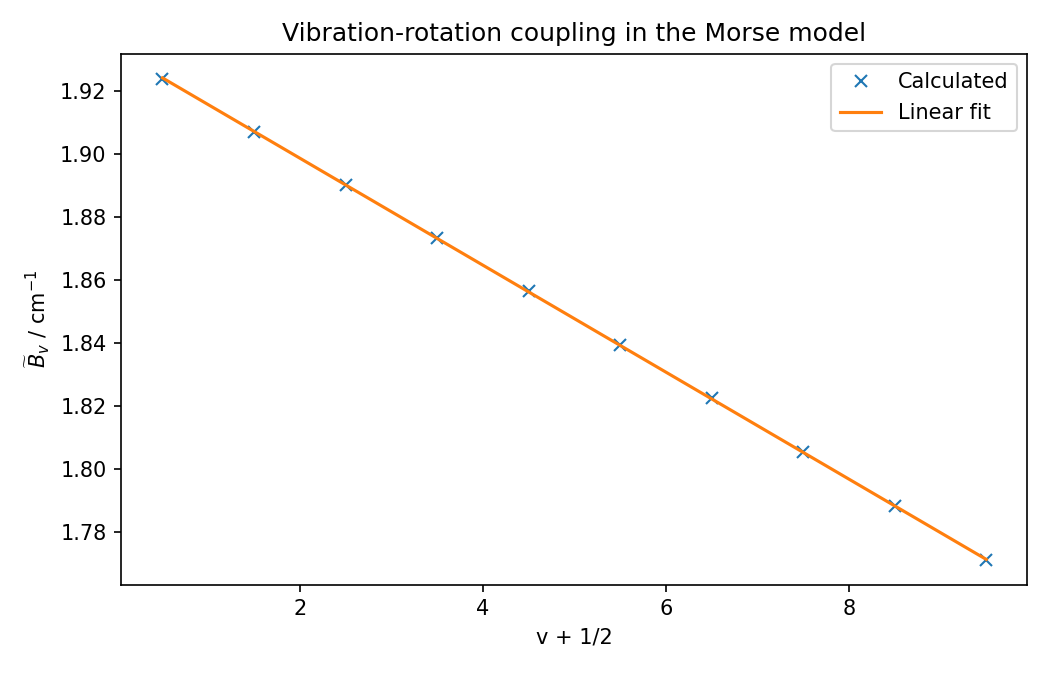

In [19]:
v_12 = morse_states + 0.5
fit = stats.linregress(v_12, B_v)
B_e = fit.intercept
alpha_e = -fit.slope
plt.figure()
plt.plot(v_12, B_v, 'x', label='Calculated')
plt.plot(v_12, fit.intercept+fit.slope*v_12, label='Linear fit')
plt.xlabel('v + 1/2')
plt.ylabel(r'$\widetilde B_v$ / cm$^{-1}$')
plt.title('Vibration-rotation coupling in the Morse model')
plt.legend()
save_figure('rotational_constant_fit')
print(f'B_e = {B_e:.8f} +/- {fit.intercept_stderr:.3g} cm^-1')
print(f'alpha_e = {alpha_e:.8f} +/- {fit.stderr:.3g} cm^-1')
print(f'R squared = {fit.rvalue**2:.10f}')

The calculated rotational constants are close to a straight line over v=0,...,9. A near-unity R² describes the fit to these model-generated values; it is not an independent experimental accuracy test.

### # Equilibrium distance inferred from the intercept

Using SI c and mass, convert the fitted $\widetilde B_e$ from cm⁻¹ to m⁻¹ before evaluating

$$r_{e,fit}=\sqrt{\frac{h}{8\pi^2 c\mu(100\widetilde B_e)}}.$$

This checks consistency with the input distance of 112.8 pm; it is not a new measured bond length.

In [20]:
re_fit_pm = np.sqrt(h/(8*np.pi**2*c*mu*(100*B_e))) * 1e12
print(f'Input equilibrium distance: {re*1e12:.6f} pm')
print(f'Fit-derived distance: {re_fit_pm:.6f} pm')
print(f'Difference: {re_fit_pm-re*1e12:+.6f} pm')
with (RESULTS / 'rotational_fit.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['B_e_cm_minus1','B_e_standard_error','alpha_e_cm_minus1','alpha_standard_error','r_squared','re_fit_pm'])
    writer.writerow([B_e,fit.intercept_stderr,alpha_e,fit.stderr,fit.rvalue**2,re_fit_pm])

Input equilibrium distance: 112.800000 pm
Fit-derived distance: 112.787026 pm
Difference: -0.012974 pm


The fit-derived equilibrium distance is close to the input value. Any small difference reflects the finite-state linear extrapolation and numerical/model assumptions; the input parameters already determine the model wave functions.